# Firms With the Highest and the Lowest Main Relevance Score, Colored by Sector

| Item | Description |
|---|---|
| Goal | One figure for the main relevance measure, the cosine similarity between a firm-level summary of 10-K Item 1s and the policy summary of legislator statements on consumer data privacy legislation: horizontal bars for the `N_FIRMS` firms with the highest score and the `N_FIRMS` with the lowest, demeaned so that zero is the mean over all sample firms, with the bar color giving the firm's NAICS sector. |
| Input | `output/T3.8.3/firm_relevance_scores_wide.csv` (T3.8.3); the CRSP-Compustat link file `crsp_compustat_link.dta` in the source data folder for each firm's Compustat NAICS code. |
| Output | `output/T3.9.2/top_and_bottom_firms.csv`: the plotted firms with their score, demeaned score, NAICS code, and sector. `output/T3.9.2/fig_top_20_and_bottom_20_firms_policy_summary_firm_summary_cosine_demeaned_by_sector.{png,svg,pdf}`. |
| Unit | A firm (gvkey) in the sample set by `SAMPLE`: all years (every fiscal year a firm filed, 1999 to 2025; 1,058 firms) or the three years (fiscal 2010, 2015, 2020; 841 firms). The sector is the firm's NAICS two-digit code as in T3.9.3. |
| Measure | `MEASURE_ID`, T3.8.3's `summaries \| policy_summary \| firm_summary`, as in T3.9.1. The bar is the firm's score minus the mean over all sample firms. |
| Colors | Sectors with at least `MIN_FIRMS_COLORED` firms among the plotted firms get their own color from `SECTOR_COLORS`; the remaining sectors are grouped as other sectors with a color of their own and named firm by firm in the Notes. |
| Wording | Every title, axis title, and legend entry spells out what is measured, as in T3.9.1. Axis titles and legend entries are in title case at the user's request; the figure title follows S3 title case. |
| Style | S3: 9 by 6 inches, Times, 0.5 cm margins, no text inside the plot, a solid BLACK zero line, a legend below the X-title naming the sectors, title and notes in Markdown below. Five sectors need five colors that stand apart, so the palette adds ORANGE and GREEN to the S3 RED, BLUE, and GREY. |

See `README.md` in the TEMP folder for the surrounding steps, `T3.8.3` for the measure, the archived `T3.9.2 - Figure - Most and Least Relevant Firms` (in `archive`) for the ten most and least relevant firms on every measure, and `T3.9.1` for the distribution of this measure.


## Step 1. Import packages


In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import Image, Markdown, display
from matplotlib.patches import Patch


## Step 2. Define file locations, the measure, the sectors, and the wording

The wording is built from the same two phrases as T3.9.1, so that the figures of the main measure say the same thing in the same words.


In [2]:
PROJECT_FOLDER = Path("/project2/njia_1089/acroh/projects/LLM-Text-Analysis-and-Synthesis")
SOURCE_DATA_FOLDER = Path("/project2/mmiric_1435/acroh/llm_method/data")
NOTEBOOK_SUBFOLDER = Path("T3 - Topic Relevance and Corporate Disclosure/TEMP")
NOTEBOOK_NAME = "T3.9.2"  # the identifier names this notebook's output folder
TEMP_OUTPUT = PROJECT_FOLDER / NOTEBOOK_SUBFOLDER / "output"
OUTPUT_FOLDER = TEMP_OUTPUT / NOTEBOOK_NAME
SCORES_FILE = TEMP_OUTPUT / "T3.8.3/firm_relevance_scores_wide.csv"
LINK_FILE = SOURCE_DATA_FOLDER / "interim/repo_data/raw/01_firm_id/crsp_compustat_link.dta"

SAMPLE = "all_years"  # the main sample; "three_years" for the three-year figures
SAMPLE_WORDS = {"three_years": "the three-year sample (fiscal years 2010, 2015, and 2020)", "all_years": "the all-years sample (every fiscal year a firm filed, 1999 to 2025)"}
MEASURE_ID = "summaries | policy_summary | firm_summary"
N_FIRMS = 20  # firms drawn at each end
MIN_FIRMS_COLORED = 3  # a sector with fewer firms among the drawn firms is grouped as other sectors
NAICS_SECTORS = {  # two-digit code -> sector name; codes that share a sector map to the same name
    "11": "Agriculture, forestry, fishing and hunting", "21": "Mining, quarrying, and oil and gas extraction", "22": "Utilities", "23": "Construction",
    "31": "Manufacturing", "32": "Manufacturing", "33": "Manufacturing", "42": "Wholesale trade", "44": "Retail trade", "45": "Retail trade",
    "48": "Transportation and warehousing", "49": "Transportation and warehousing", "51": "Information", "52": "Finance and insurance",
    "53": "Real estate and rental and leasing", "54": "Professional, scientific, and technical services", "55": "Management of companies and enterprises",
    "56": "Administrative and support and waste management", "61": "Educational services", "62": "Health care and social assistance",
    "71": "Arts, entertainment, and recreation", "72": "Accommodation and food services", "81": "Other services", "92": "Public administration",
    "99": "Unclassified",
}
SECTOR_LEGEND = {  # sector -> legend words with the NAICS code
    "Information": "Information Sector (NAICS 51)",
    "Finance and insurance": "Finance and Insurance Sector (NAICS 52)",
    "Manufacturing": "Manufacturing Sector (NAICS 31 to 33)",
    "Mining, quarrying, and oil and gas extraction": "Mining, Quarrying, and Oil and Gas Extraction Sector (NAICS 21)",
}
OTHER_SECTORS = "Other sectors"
OTHER_SECTORS_LEGEND = "Other Sectors (Named in the Notes)"

# Wording. The two texts compared, in title case, then the titles built from them.
FIRM_SUMMARY_TITLE = "a Firm-Level Summary of 10-K Item 1s"
POLICY_SUMMARY_TITLE = "the Policy Summary of Legislator Statements on Consumer Data Privacy Legislation"
SCORE_TITLE = f"Cosine Similarity Between {FIRM_SUMMARY_TITLE} and {POLICY_SUMMARY_TITLE}"
FIGURE_TITLE = (f"The {N_FIRMS} Firms With the Highest and the {N_FIRMS} Firms With the Lowest {SCORE_TITLE}, "
                "Relative to the Mean Over All Firms, by Sector")
Y_TITLE = "Firm Name"
SCORE_WORDS = ("the cosine similarity between two embeddings: the firm-level summary, one paragraph written by the language model that condenses the firm's "
               "yearly summaries of its 10-K Item 1 (Business) sections over its fiscal years in the sample, and the policy summary, one text written by the "
               "language model that condenses the legislator statements on Topic 68, consumer data privacy legislation, extracted from congressional hearings. "
               "A higher score means that the firm's business description is closer to the policy summary")
FIGURE_NAME = f"fig_top_{N_FIRMS}_and_bottom_{N_FIRMS}_firms_policy_summary_firm_summary_cosine_demeaned_by_sector"
SOURCE = "10-K Item 1 sections from SEC EDGAR; congressional hearing statements from GovInfo; NAICS codes from Compustat through the CRSP-Compustat link; authors' calculations"
OUTPUT_FOLDER.mkdir(parents=True, exist_ok=True)
print(f"Outputs: {OUTPUT_FOLDER}")


Outputs: /project2/njia_1089/acroh/projects/LLM-Text-Analysis-and-Synthesis/T3 - Topic Relevance and Corporate Disclosure/TEMP/output/T3.9.2


## Step 3. Figure style

The S3 settings: canvas, font, colors, horizontal background lines only. Information keeps RED and mining BLUE as in T3.9.1; manufacturing takes ORANGE, finance and insurance GREEN, and the grouped other sectors GREY, so that the five groups stand apart at a glance. The firm names are set at a smaller size so that forty rows fit the canvas.


In [3]:
RED = "#B31942"
BLUE = "#0A3161"
MIDNIGHT_BLUE = "#004953"
GREY = "#A6A6A8"
BLACK = "#101820"
ORANGE = "#E69F00"  # manufacturing
GREEN = "#3B7A58"  # finance and insurance
FIGURE_WIDTH = 9
FIGURE_HEIGHT = 6
MARGIN_INCHES = 0.5 / 2.54
ZERO_LINE_WIDTH = 0.8 / 3  # S3 zero line
BAR_HEIGHT = 0.75
FIRM_LABEL_SIZE = 7.5
LEGEND_FONT_SIZE = 10
EXPORT_DPI = 300
SECTOR_COLORS = {"Information": RED, "Mining, quarrying, and oil and gas extraction": BLUE, "Manufacturing": ORANGE, "Finance and insurance": GREEN, OTHER_SECTORS: GREY}

plt.rcParams["font.family"] = "serif"
plt.rcParams["font.serif"] = ["Times New Roman", "Times", "Liberation Serif", "DejaVu Serif"]
plt.rcParams["font.size"] = 11
plt.rcParams["figure.figsize"] = (FIGURE_WIDTH, FIGURE_HEIGHT)
plt.rcParams["figure.facecolor"] = "white"
plt.rcParams["axes.facecolor"] = "white"
plt.rcParams["axes.unicode_minus"] = True
plt.rcParams["axes.grid"] = True
plt.rcParams["axes.grid.axis"] = "y"
plt.rcParams["axes.axisbelow"] = True
plt.rcParams["grid.color"] = GREY
plt.rcParams["grid.linewidth"] = 0.5
plt.rcParams["text.color"] = BLACK
plt.rcParams["axes.labelcolor"] = BLACK
plt.rcParams["axes.edgecolor"] = BLACK
plt.rcParams["xtick.color"] = BLACK
plt.rcParams["ytick.color"] = BLACK


## Step 4. Load the scores, tidy the firm names, and attach a NAICS sector

The wide table of T3.8.3, the chosen sample only. Compustat names are upper case; they are shown in title case with the common suffixes kept short, as in the archived T3.9.2. The sector comes from the link file exactly as in T3.9.3.


In [4]:
wide = pd.read_csv(SCORES_FILE, dtype={"gvkey": str})
wide = wide.loc[wide["sample"].eq(SAMPLE)].reset_index(drop=True)
assert MEASURE_ID in wide.columns, MEASURE_ID
assert wide[MEASURE_ID].notna().all(), f"{int(wide[MEASURE_ID].isna().sum())} firms without a score"
wide["display_name"] = wide["conm"].str.title().str.replace(r"\s+-Cl\s+\w+$", "", regex=True).str.replace(r"\bInc$", "Inc.", regex=True).str.replace(r"\bCorp$", "Corp.", regex=True)
assert wide["display_name"].is_unique, "two firms would share a label"

link = pd.read_stata(LINK_FILE, columns=["GVKEY", "naics"])
link["gvkey"] = link["GVKEY"].astype(str).str.zfill(6)
link["naics"] = link["naics"].astype(str).str.strip().replace({"": None, "nan": None})
link = link.dropna(subset=["naics"])
assert link.groupby("gvkey")["naics"].nunique().le(1).all(), "a gvkey with two NAICS codes"
naics = link.drop_duplicates("gvkey").set_index("gvkey")["naics"]
wide["naics"] = wide["gvkey"].map(naics)
assert wide["naics"].notna().all(), f"{int(wide['naics'].isna().sum())} firms without a NAICS code"
wide["naics2"] = wide["naics"].str[:2]
assert wide["naics2"].isin(NAICS_SECTORS).all(), sorted(set(wide["naics2"]) - set(NAICS_SECTORS))
wide["sector"] = wide["naics2"].map(NAICS_SECTORS)
print(f"Firms in the {SAMPLE} sample: {len(wide):,}")


Firms in the all_years sample: 1,058


## Step 5. Pick the firms at both ends, demean, and assign the color groups

The score minus the mean over all sample firms; the `N_FIRMS` highest and the `N_FIRMS` lowest, each group ordered from the highest to the lowest score. A sector with at least `MIN_FIRMS_COLORED` of the drawn firms gets its own color and must have one in `SECTOR_COLORS`; the rest are grouped as other sectors. The drawn firms are saved.


In [5]:
population_mean = float(wide[MEASURE_ID].mean())
wide["demeaned"] = wide[MEASURE_ID] - population_mean
ranked = wide.sort_values(MEASURE_ID, ascending=False).reset_index(drop=True)
assert ranked[MEASURE_ID].iloc[N_FIRMS - 1] > ranked[MEASURE_ID].iloc[N_FIRMS], "a tie at the top cutoff"
assert ranked[MEASURE_ID].iloc[-N_FIRMS] < ranked[MEASURE_ID].iloc[-N_FIRMS - 1], "a tie at the bottom cutoff"
top = ranked.head(N_FIRMS).assign(group="highest")
bottom = ranked.tail(N_FIRMS).assign(group="lowest")
drawn = pd.concat([top, bottom]).reset_index(drop=True)

sector_counts = drawn["sector"].value_counts()
colored_sectors = [sector for sector in SECTOR_LEGEND if sector_counts.get(sector, 0) >= MIN_FIRMS_COLORED]  # legend order
grouped_sectors = sorted(sector_counts.index[sector_counts < MIN_FIRMS_COLORED])
assert set(sector_counts.index[sector_counts >= MIN_FIRMS_COLORED]) == set(colored_sectors), "a sector with enough firms has no legend entry"
assert set(colored_sectors) <= set(SECTOR_COLORS), set(colored_sectors) - set(SECTOR_COLORS)
drawn["color_group"] = np.where(drawn["sector"].isin(colored_sectors), drawn["sector"], OTHER_SECTORS)
drawn[["gvkey", "conm", "display_name", "naics", "naics2", "sector", "color_group", "group", MEASURE_ID, "demeaned"]].to_csv(OUTPUT_FOLDER / "top_and_bottom_firms.csv", index=False, float_format="%.6f")
print(f"Mean over all {len(wide):,} firms: {population_mean:.4f}; highest {top[MEASURE_ID].iloc[0]:.4f} ({top['display_name'].iloc[0]}); "
      f"lowest {bottom[MEASURE_ID].iloc[-1]:.4f} ({bottom['display_name'].iloc[-1]})")
print(f"Colored sectors: {', '.join(f'{s} ({sector_counts[s]})' for s in colored_sectors)}; grouped as other sectors: {', '.join(f'{s} ({sector_counts[s]})' for s in grouped_sectors) or 'none'}")
display(drawn[["display_name", "naics2", "sector", "group", MEASURE_ID, "demeaned"]].round(4))


Mean over all 1,058 firms: 0.5121; highest 0.6209 (Visa Inc.); lowest 0.4034 (Alpha Natural Resources Inc.)
Colored sectors: Information (7), Finance and insurance (7), Manufacturing (10), Mining, quarrying, and oil and gas extraction (10); grouped as other sectors: Administrative and support and waste management (1), Professional, scientific, and technical services (2), Retail trade (1), Transportation and warehousing (1), Wholesale trade (1)


,display_name,naics2,sector,group,summaries | policy_summary | firm_summary,demeaned
0,Visa Inc.,52,Finance and insurance,highest,0.6209,0.1088
1,Palantir Technolog Inc.,51,Information,highest,0.6165,0.1044
2,Gen Digital Inc.,51,Information,highest,0.6162,0.1041
3,Comverse Technology Inc.,51,Information,highest,0.6132,0.1011
4,Nielsen Holdings Plc,54,"Professional, scientific, and technical services",highest,0.6131,0.1010
5,Dell Technologies Inc.,33,Manufacturing,highest,0.6112,0.0991
6,Charter One Financial Inc.,52,Finance and insurance,highest,0.6103,0.0982
7,Alphabet Inc.,51,Information,highest,0.6094,0.0973
8,Verizon Communications Inc.,51,Information,highest,0.6070,0.0949
9,Motorola Mobility Hldgs Inc.,33,Manufacturing,highest,0.6063,0.0942


## Step 6. Draw the figure

One horizontal bar per firm, the highest score at the top and the lowest at the bottom with an empty row between the two groups, bars running from zero (the mean over all firms) to the firm's demeaned score, colored by sector, with a solid BLACK zero line. No text inside the plot. The legend names the sectors with their NAICS codes and sits 0.5 cm above the bottom edge with the most columns that fit between the side margins; the X-title ends 0.5 cm above the legend and the firm names start 0.5 cm from the left edge after the Y-title.


In [6]:
labels = top["display_name"].tolist() + [""] + bottom["display_name"].tolist()
positions = np.arange(len(labels))[::-1]  # first label at the top
bar_positions = np.concatenate([positions[:N_FIRMS], positions[N_FIRMS + 1:]])
bar_colors = [SECTOR_COLORS[group] for group in drawn["color_group"]]
reach = float(drawn["demeaned"].abs().max()) * 1.05
x_title = f"{SCORE_TITLE.replace(' and the Policy', chr(10) + 'and the Policy')}, Minus Sample Mean"  # two lines

figure, axis = plt.subplots()
figure.subplots_adjust(left=0.25, right=1 - MARGIN_INCHES / FIGURE_WIDTH, top=1 - MARGIN_INCHES / FIGURE_HEIGHT, bottom=0.3)
axis.barh(bar_positions, drawn["demeaned"], color=bar_colors, height=BAR_HEIGHT, zorder=2)
axis.axvline(0, color=BLACK, linewidth=ZERO_LINE_WIDTH, zorder=3)
axis.set_yticks(positions, labels=labels)
axis.set_ylim(positions.min() - 0.6, positions.max() + 0.6)
axis.set_xlim(-reach, reach)
axis.set_xlabel(x_title)
axis.set_ylabel(Y_TITLE)
axis.tick_params(axis="y", length=0, labelsize=FIRM_LABEL_SIZE)
axis.spines[["top", "right"]].set_visible(False)
legend_handles = [Patch(facecolor=SECTOR_COLORS[sector]) for sector in colored_sectors] + ([Patch(facecolor=SECTOR_COLORS[OTHER_SECTORS])] if grouped_sectors else [])
legend_labels = [SECTOR_LEGEND[sector] for sector in colored_sectors] + ([OTHER_SECTORS_LEGEND] if grouped_sectors else [])

figure.canvas.draw()
renderer = figure.canvas.get_renderer()
margin_pixels = MARGIN_INCHES * figure.dpi
x_title_box = axis.xaxis.label.get_window_extent(renderer)
assert x_title_box.width <= figure.bbox.width - 2 * margin_pixels, f"X-title is {x_title_box.width / figure.dpi:.2f} inches wide"
for n_columns in range(len(legend_labels), 0, -1):  # the most columns that fit within the side margins
    legend = figure.legend(legend_handles, legend_labels, loc="lower center", bbox_to_anchor=(0.5, MARGIN_INCHES / FIGURE_HEIGHT),
                           bbox_transform=figure.transFigure, ncol=n_columns, frameon=False, fontsize=LEGEND_FONT_SIZE, borderaxespad=0)
    figure.canvas.draw()
    if legend.get_window_extent(renderer).width <= figure.bbox.width - 2 * margin_pixels:
        break
    legend.remove()
left_shift = (margin_pixels - axis.yaxis.label.get_window_extent(renderer).x0) / figure.bbox.width
bottom_shift = (legend.get_window_extent(renderer).y1 + margin_pixels - x_title_box.y0) / figure.bbox.height
figure.subplots_adjust(left=figure.subplotpars.left + left_shift, bottom=figure.subplotpars.bottom + bottom_shift)
figure.canvas.draw()
row_height = axis.get_window_extent(renderer).height / len(labels) / figure.dpi
for extension in ["png", "svg", "pdf"]:
    figure.savefig(OUTPUT_FOLDER / f"{FIGURE_NAME}.{extension}", dpi=EXPORT_DPI)
plt.close(figure)

other_words = "; ".join(f"{name} ({sector.lower()})" for name, sector in zip(drawn.loc[drawn["color_group"].eq(OTHER_SECTORS), "display_name"], drawn.loc[drawn["color_group"].eq(OTHER_SECTORS), "sector"]))
notes = (f"Each bar is the firm's score minus the sample mean, the mean over all {len(wide):,} firms of {SAMPLE_WORDS[SAMPLE]}, {population_mean:.3f}: zero is the sample mean, "
         f"a bar to the right is a firm above it and a bar to the left a firm below it. The {N_FIRMS} firms with the highest score are at the top and the {N_FIRMS} "
         f"with the lowest at the bottom, each group ordered from the highest to the lowest, with an empty row between them. The score is {SCORE_WORDS}. "
         f"The bar color is the firm's NAICS sector from Compustat, cut to two digits; sectors with fewer than {MIN_FIRMS_COLORED} of the {2 * N_FIRMS} drawn firms are grouped "
         f"as other sectors: {other_words}. Firm names are Compustat names in title case.")
print(f"Figure: {FIGURE_NAME} ({len(drawn)} firms; {row_height:.3f} inches per row; X-title {x_title_box.width / figure.dpi:.2f} inches wide; legend in {n_columns} columns)")


Figure: fig_top_20_and_bottom_20_firms_policy_summary_firm_summary_cosine_demeaned_by_sector (40 firms; 0.101 inches per row; X-title 6.81 inches wide; legend in 2 columns)


## Step 7. Show the figure

Title, image, Notes, and Source, in that order.


**Figure 1. The 20 Firms With the Highest and the 20 Firms With the Lowest Cosine Similarity Between a Firm-Level Summary of 10-K Item 1s and the Policy Summary of Legislator Statements on Consumer Data Privacy Legislation, Relative to the Mean Over All Firms, by Sector**

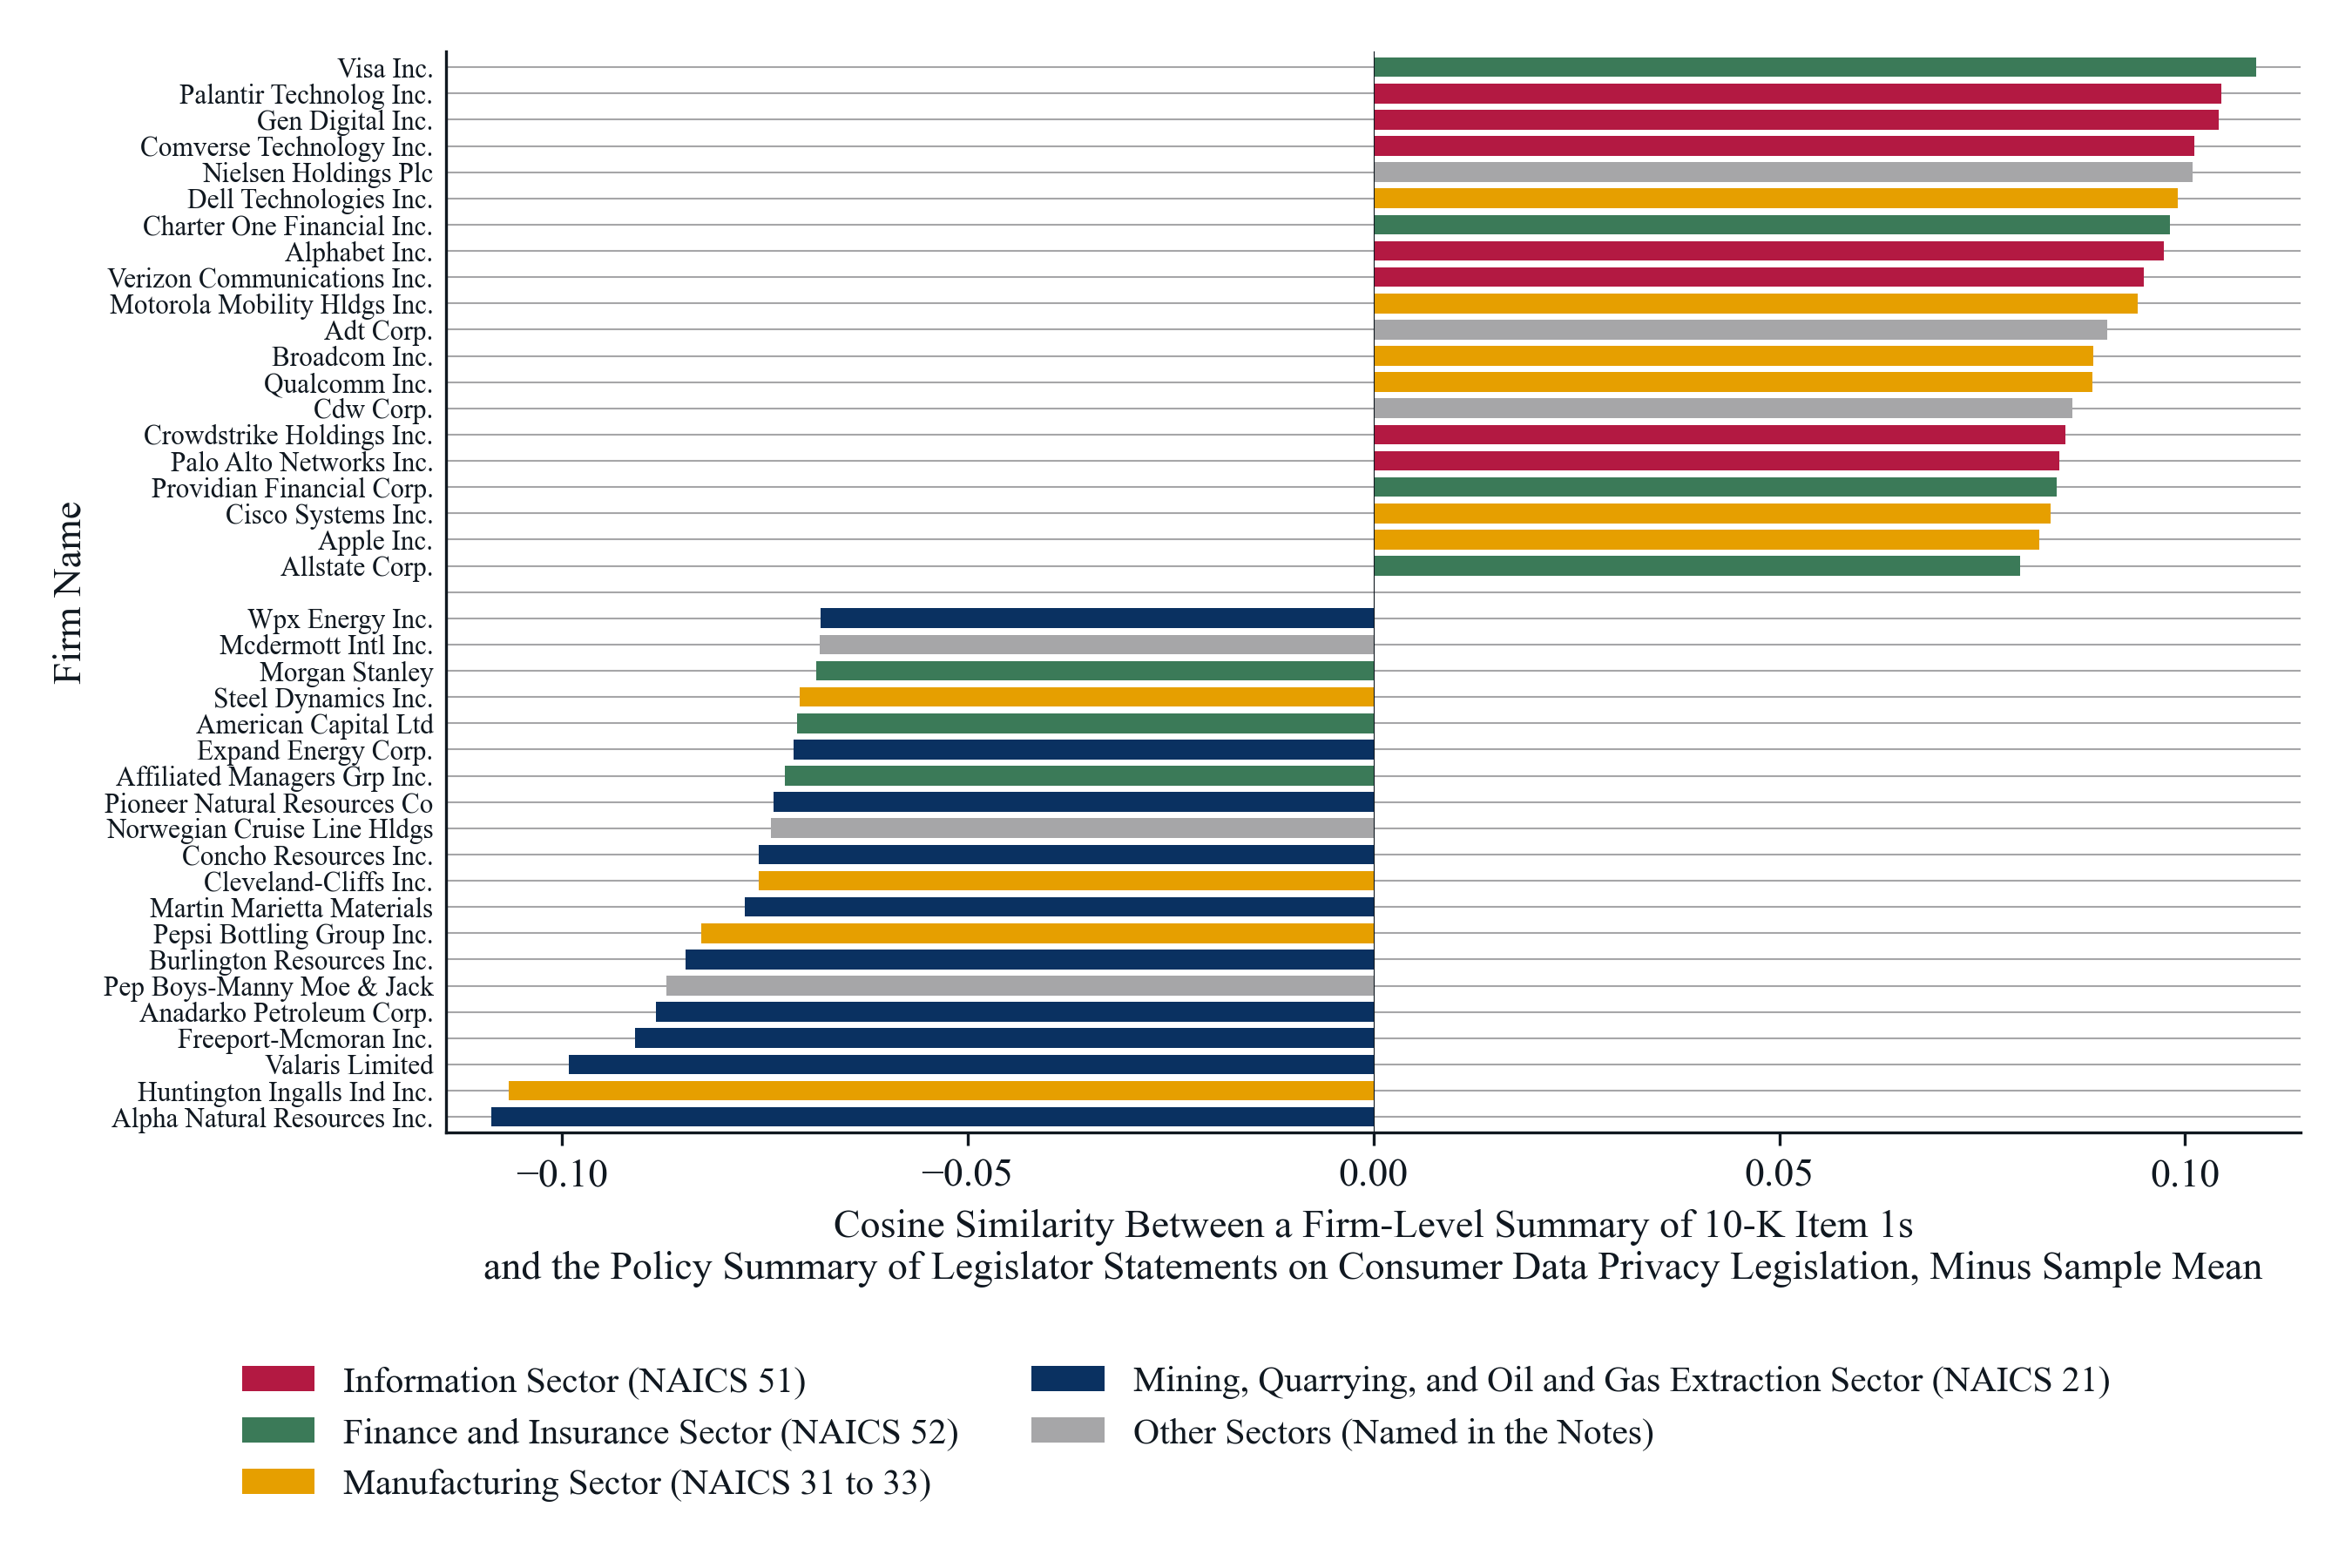

*Notes*: Each bar is the firm's score minus the sample mean, the mean over all 1,058 firms of the all-years sample (every fiscal year a firm filed, 1999 to 2025), 0.512: zero is the sample mean, a bar to the right is a firm above it and a bar to the left a firm below it. The 20 firms with the highest score are at the top and the 20 with the lowest at the bottom, each group ordered from the highest to the lowest, with an empty row between them. The score is the cosine similarity between two embeddings: the firm-level summary, one paragraph written by the language model that condenses the firm's yearly summaries of its 10-K Item 1 (Business) sections over its fiscal years in the sample, and the policy summary, one text written by the language model that condenses the legislator statements on Topic 68, consumer data privacy legislation, extracted from congressional hearings. A higher score means that the firm's business description is closer to the policy summary. The bar color is the firm's NAICS sector from Compustat, cut to two digits; sectors with fewer than 3 of the 40 drawn firms are grouped as other sectors: Nielsen Holdings Plc (professional, scientific, and technical services); Adt Corp. (administrative and support and waste management); Cdw Corp. (wholesale trade); Mcdermott Intl Inc. (professional, scientific, and technical services); Norwegian Cruise Line Hldgs (transportation and warehousing); Pep Boys-Manny Moe & Jack (retail trade). Firm names are Compustat names in title case.

*Source*: 10-K Item 1 sections from SEC EDGAR; congressional hearing statements from GovInfo; NAICS codes from Compustat through the CRSP-Compustat link; authors' calculations.

In [7]:
display(Markdown(f"**Figure 1. {FIGURE_TITLE}**"))
display(Image(filename=str(OUTPUT_FOLDER / f"{FIGURE_NAME}.png"), width=900))
display(Markdown(f"*Notes*: {notes}"))
display(Markdown(f"*Source*: {SOURCE}."))
